# U01 — Temporal method selection

U00 showed that temporal intervention is powerful but trajectory-dependent. U01 selects a **small robust bank** rather than one universal setting.

Procedure:

1. Carry forward 5 promising U00 methods.
2. Add 5 new schedules with gradual/nonlinear attenuation.
3. Plot generation-token position \(t\) vs full-history coefficient \(\lambda(t)\).
4. Run all 10 methods on 10 fresh fixed-54 prompts.
5. Rank only by non-EOS count; drop the bottom two only when strictly worse. Ties at the 8th-place cutoff survive.
6. Run all survivors on 10 additional fresh prompts.
7. Measure frozen \(U(128)\) and graph \(\Delta U(128)=U_{\text{method}}-U_{\text{Full}}\).
8. Manually inspect prose for lobotomization/content loss.

No Ghostbuster, Unique controller, or NFZ suffix is used for U01 selection.

Here \(\lambda(t)\) is the **full-history coefficient**:

\[
q_t=\lambda(t)p_{\rm full}+(1-\lambda(t))p_{K=64}.
\]

So \(\lambda=1\) means ordinary full history and \(\lambda=0\) means hard K64 at that token.


In [1]:
from pathlib import Path
import gc,math,hashlib,json,html
import numpy as np,pandas as pd,torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer,AutoModelForCausalLM
from IPython.display import display,HTML

ROOT=Path.cwd().resolve()
if ROOT.name=="experiments":ROOT=ROOT.parent
if not (ROOT/"results").exists() and (ROOT.parent/"results").exists():ROOT=ROOT.parent
assert (ROOT/"results").exists(),ROOT

U00=ROOT/"results/causal/U00_soft_history_bruteforce"
OUT=ROOT/"results/causal/U01_temporal_method_selection";OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/"figures";FIG.mkdir(exist_ok=True)

SEED=20260915
GENERATOR="Qwen/Qwen2.5-1.5B-Instruct"
SCORER="Qwen/Qwen3-0.6B-Base"
MAX_NEW_TOKENS=480
K=64
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype=torch.float16 if device.type=="cuda" else torch.float32

PROMPTS=U00/"fixed54_prompts.parquet"
assert PROMPTS.exists(),f"Missing U00 prompt cache: {PROMPTS}"
prompts54=pd.read_parquet(PROMPTS)
assert len(prompts54)==54

print("ROOT:",ROOT)
print("OUT:",OUT)
print("fixed54 prompts:",len(prompts54))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
OUT: ../results/causal/U01_temporal_method_selection
fixed54 prompts: 54


## Ten candidate schedules

Five carried forward from U00:

- `STEP75`: prior S64_025, i.e. \(\lambda=1\) before token 64, then .75.
- `STEP80`: prior S64_020.
- `STEP825`: prior S64_0175.
- `PULSE8`: hard K64 every 8 generated tokens after token 64.
- `PULSE16`: hard K64 every 16 generated tokens after token 64.

Five new schedules:

- `LINEAR75`: linear decay from 1 at token 64 to .75 at token 192.
- `LINEAR80`: same but floor .80.
- `SIG_EARLY75`: early sigmoid decay toward .75.
- `SIG_LATE75`: later sigmoid decay toward .75.
- `RECOVER75_90`: strong mid-generation suppression, then gradual recovery toward .90 late to protect coherence/EOS.


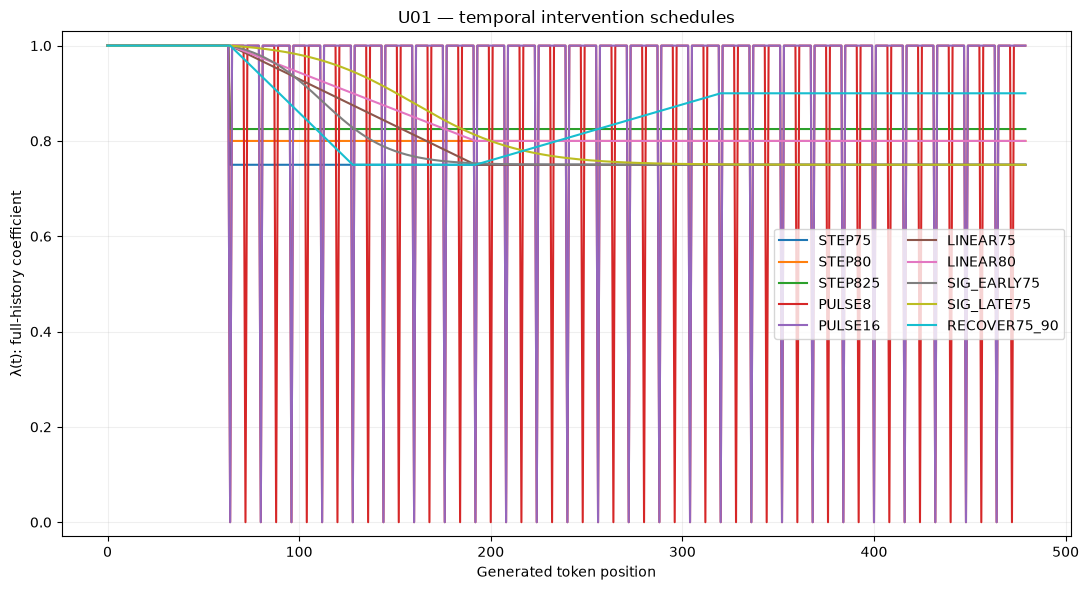

In [2]:
METHODS=[
    "STEP75","STEP80","STEP825","PULSE8","PULSE16",
    "LINEAR75","LINEAR80","SIG_EARLY75","SIG_LATE75","RECOVER75_90"
]

def norm_sigmoid(t,floor,center,scale,start=64):
    if t<=start:return 1.0
    s=lambda x:1/(1+math.exp((x-center)/scale))
    return float(np.clip(floor+(1-floor)*s(t)/s(start),floor,1.0))

def lambda_full(method,t):
    if t<64:return 1.0
    if method=="STEP75":return .75
    if method=="STEP80":return .80
    if method=="STEP825":return .825
    if method=="PULSE8":return 0.0 if (t-64)%8==0 else 1.0
    if method=="PULSE16":return 0.0 if (t-64)%16==0 else 1.0
    if method=="LINEAR75":return .75 if t>=192 else 1-.25*(t-64)/128
    if method=="LINEAR80":return .80 if t>=192 else 1-.20*(t-64)/128
    if method=="SIG_EARLY75":return norm_sigmoid(t,.75,112,18)
    if method=="SIG_LATE75":return norm_sigmoid(t,.75,160,28)
    if method=="RECOVER75_90":
        if t<128:return 1-.25*(t-64)/64
        if t<192:return .75
        if t<320:return .75+.15*(t-192)/128
        return .90
    raise KeyError(method)

schedule=pd.DataFrame(
    [(m,t,lambda_full(m,t)) for m in METHODS for t in range(MAX_NEW_TOKENS)],
    columns=["method","token","lambda_full"]
)
schedule.to_csv(OUT/"temporal_schedule_lines.csv",index=False)

fig,ax=plt.subplots(figsize=(11,6))
for m in METHODS:
    z=schedule[schedule.method.eq(m)]
    ax.plot(z.token,z.lambda_full,label=m)
ax.set(xlabel="Generated token position",ylabel="λ(t): full-history coefficient",
       title="U01 — temporal intervention schedules",ylim=(-.03,1.03))
ax.grid(alpha=.2);ax.legend(ncol=2);fig.tight_layout()
for folder in [OUT,FIG]:
    fig.savefig(folder/"U01_temporal_schedule_lines.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U01_temporal_schedule_lines.pdf",bbox_inches="tight")
plt.show()


## Freeze 20 fresh cases

U01 excludes sources already used in U00 whenever the U00 checkpoint is available. The first 10 become Stage 1 and the next 10 Stage 2.


In [3]:
used=set()
for p in U00.glob("u00_*generations*_checkpoint.parquet"):
    try:used.update(pd.read_parquet(p,columns=["source_id"]).source_id.astype(str))
    except Exception:pass

COHORT_PATH=OUT/"cohort20.csv"
if COHORT_PATH.exists():
    cohort20=pd.read_csv(COHORT_PATH,keep_default_na=False)
else:
    pool=prompts54[~prompts54.source_id.astype(str).isin(used)].copy()
    rng=np.random.default_rng(SEED+201)
    groups={}
    for d,g in pool.groupby("domain"):
        groups[d]=g.iloc[rng.permutation(len(g))].reset_index(drop=True)
    domains=sorted(groups);rows=[];cursor={d:0 for d in domains}
    while len(rows)<20:
        progressed=False
        for d in domains:
            j=cursor[d]
            if j<len(groups[d]):
                rows.append(groups[d].iloc[j]);cursor[d]+=1;progressed=True
                if len(rows)==20:break
        if not progressed:break
    cohort20=pd.DataFrame(rows).drop_duplicates("source_id").head(20).reset_index(drop=True)
    assert len(cohort20)==20,(len(cohort20),len(pool),len(used))
    cohort20["stage"]=np.where(np.arange(20)<10,1,2)
    cohort20.to_csv(COHORT_PATH,index=False)

stage1=cohort20[cohort20.stage.eq(1)].copy()
stage2=cohort20[cohort20.stage.eq(2)].copy()
display(cohort20[["stage","case_id","source_id","domain"]])


,stage,case_id,source_id,domain
0,1,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,1,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,1,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,1,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,1,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,1,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,1,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,1,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,1,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


## Generator

The full branch always follows the actually generated candidate prefix. The K64 branch is recomputed from `[prompt ; last 64 generated tokens]`. When \(\lambda(t)=1\), the capped branch is skipped.


In [4]:
gtok=AutoTokenizer.from_pretrained(GENERATOR,use_fast=True)
gmodel=AutoModelForCausalLM.from_pretrained(
    GENERATOR,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

def make_prompt_ids(prompt):
    text=gtok.apply_chat_template(
        [{"role":"user","content":str(prompt)}],
        tokenize=False,add_generation_prompt=True
    )
    return gtok(text,return_tensors="pt",add_special_tokens=False)["input_ids"].to(device)

eos=gmodel.generation_config.eos_token_id
if eos is None:eos=gtok.eos_token_id
EOS=set(eos if isinstance(eos,(list,tuple)) else [eos])

@torch.inference_mode()
def generate_full(prompt):
    p=make_prompt_ids(prompt);out=gmodel(input_ids=p,use_cache=True)
    logits=out.logits[:,-1,:].float();past=out.past_key_values;gen=[]
    for _ in range(MAX_NEW_TOKENS):
        nxt=int(logits.argmax(-1).item())
        if nxt in EOS:return gen,"eos"
        gen.append(nxt)
        out=gmodel(input_ids=torch.tensor([[nxt]],device=device),past_key_values=past,use_cache=True)
        logits=out.logits[:,-1,:].float();past=out.past_key_values
    return gen,"max_tokens"

@torch.inference_mode()
def generate_method(prompt,method):
    p0=make_prompt_ids(prompt);p=p0[0].tolist()
    out=gmodel(input_ids=p0,use_cache=True)
    full_logits=out.logits[:,-1,:].float();past=out.past_key_values
    gen=[];first=None;overrides=0;active=0;sum_lam=0.

    for t in range(MAX_NEW_TOKENS):
        lam=float(lambda_full(method,t));sum_lam+=lam
        full_choice=int(full_logits.argmax(-1).item())
        if lam>=1-1e-12:
            nxt=full_choice
        else:
            active+=1
            cap=torch.tensor([p+gen[-K:]],device=device)
            cap_logits=gmodel(input_ids=cap,use_cache=False).logits[:,-1,:].float()
            if lam<=1e-12:
                nxt=int(cap_logits.argmax(-1).item())
            else:
                lq=torch.logaddexp(
                    F.log_softmax(full_logits,-1)+math.log(lam),
                    F.log_softmax(cap_logits,-1)+math.log1p(-lam)
                )
                nxt=int(lq.argmax(-1).item())

        if nxt!=full_choice:
            overrides+=1
            if first is None:first=t
        if nxt in EOS:return gen,"eos",first,active,overrides,sum_lam/max(1,t+1)

        gen.append(nxt)
        out=gmodel(input_ids=torch.tensor([[nxt]],device=device),past_key_values=past,use_cache=True)
        full_logits=out.logits[:,-1,:].float();past=out.past_key_values

    return gen,"max_tokens",first,active,overrides,sum_lam/MAX_NEW_TOKENS

print("Generator ready:",GENERATOR)


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 1141.20it/s]


Generator ready: Qwen/Qwen2.5-1.5B-Instruct


## Stage 1 — all 10 methods × 10 fresh cases

In [5]:
S1_PATH=OUT/"stage1_generations.parquet"
s1=pd.read_parquet(S1_PATH) if S1_PATH.exists() else pd.DataFrame()
done=set(zip(s1.source_id.astype(str),s1.method.astype(str))) if len(s1) else set()
rows=s1.to_dict("records") if len(s1) else []
required=["FULL"]+METHODS
pbar=tqdm(total=len(stage1)*len(required),initial=len(done),desc="U01 stage1")

for src in stage1.itertuples(index=False):
    for method in required:
        key=(str(src.source_id),method)
        if key in done:continue
        if method=="FULL":
            ids,stop=generate_full(src.prompt);first=np.nan;active=0;over=0;mean_lam=1.
        else:
            ids,stop,first,active,over,mean_lam=generate_method(src.prompt,method)
        text=gtok.decode(ids,skip_special_tokens=True)
        rows.append({
            "stage":1,"case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "method":method,"generated_text":text,"generator_tokens":len(ids),
            "stop_reason":stop,"first_override_step":first,"active_steps":active,
            "override_count":over,"mean_lambda_full":mean_lam,
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })
        s1=pd.DataFrame(rows);s1.to_parquet(S1_PATH,index=False);pbar.update(1)

pbar.close()
assert len(s1)==len(stage1)*len(required)

stage1_rank=(
    s1[s1.method.ne("FULL")].groupby("method")
    .agg(non_eos=("stop_reason",lambda x:(x!="eos").sum()),
         eos_rate=("stop_reason",lambda x:(x=="eos").mean()),
         mean_tokens=("generator_tokens","mean"),
         mean_overrides=("override_count","mean"))
    .reset_index().sort_values(["non_eos","mean_tokens","method"])
)

cutoff=int(stage1_rank.iloc[7].non_eos)
stage1_rank["survives"]=stage1_rank.non_eos.le(cutoff)
survivors=stage1_rank.loc[stage1_rank.survives,"method"].tolist()

stage1_rank.to_csv(OUT/"stage1_eos_ranking.csv",index=False)
(OUT/"stage1_survivors.json").write_text(json.dumps(survivors,indent=2))

display(stage1_rank)
print("8th-place non-EOS cutoff:",cutoff)
print("Survivors:",survivors)


U01 stage1: 100%|█████████████████████████████████████████████████████████████████████████████████████| 110/110 [22:29<00:00, 12.26s/it]


,method,non_eos,eos_rate,mean_tokens,mean_overrides,survives
4,RECOVER75_90,3,0.7,329.9,3.8,True
1,LINEAR80,3,0.7,333.4,3.8,True
5,SIG_EARLY75,3,0.7,333.5,4.3,True
0,LINEAR75,3,0.7,337.2,4.4,True
6,SIG_LATE75,3,0.7,341.9,3.5,True
3,PULSE8,4,0.6,336.7,3.9,True
2,PULSE16,4,0.6,337.8,2.5,True
9,STEP825,4,0.6,338.8,4.4,True
8,STEP80,4,0.6,339.3,4.0,True
7,STEP75,4,0.6,340.8,5.4,True


8th-place non-EOS cutoff: 4
Survivors: ['RECOVER75_90', 'LINEAR80', 'SIG_EARLY75', 'LINEAR75', 'SIG_LATE75', 'PULSE8', 'PULSE16', 'STEP825', 'STEP80', 'STEP75']


## Stage-1 frozen \(U(128)\) and \(\Delta U\) graph

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3045.61it/s]


,method,eligible_n,mean_delta_U128,median_delta_U128,negative_fraction,non_eos,eos_rate,mean_tokens,mean_overrides,survives
9,RECOVER75_90,7,-0.200942,-0.208875,0.571429,3,0.7,329.9,3.8,True
4,PULSE16,7,-0.193077,-0.254756,0.571429,4,0.6,337.8,2.5,True
7,SIG_EARLY75,7,-0.177448,-0.113534,0.714286,3,0.7,333.5,4.3,True
0,STEP75,7,-0.081602,-0.367434,0.714286,4,0.6,340.8,5.4,True
6,LINEAR80,7,-0.038846,0.000000,0.285714,3,0.7,333.4,3.8,True
8,SIG_LATE75,7,-0.007737,0.000000,0.285714,3,0.7,341.9,3.5,True
5,LINEAR75,7,0.078849,-0.043938,0.571429,3,0.7,337.2,4.4,True
3,PULSE8,7,0.095182,0.068764,0.285714,4,0.6,336.7,3.9,True
1,STEP80,7,0.134646,0.000000,0.428571,4,0.6,339.3,4.0,True
2,STEP825,7,0.265463,0.000000,0.428571,4,0.6,338.8,4.4,True


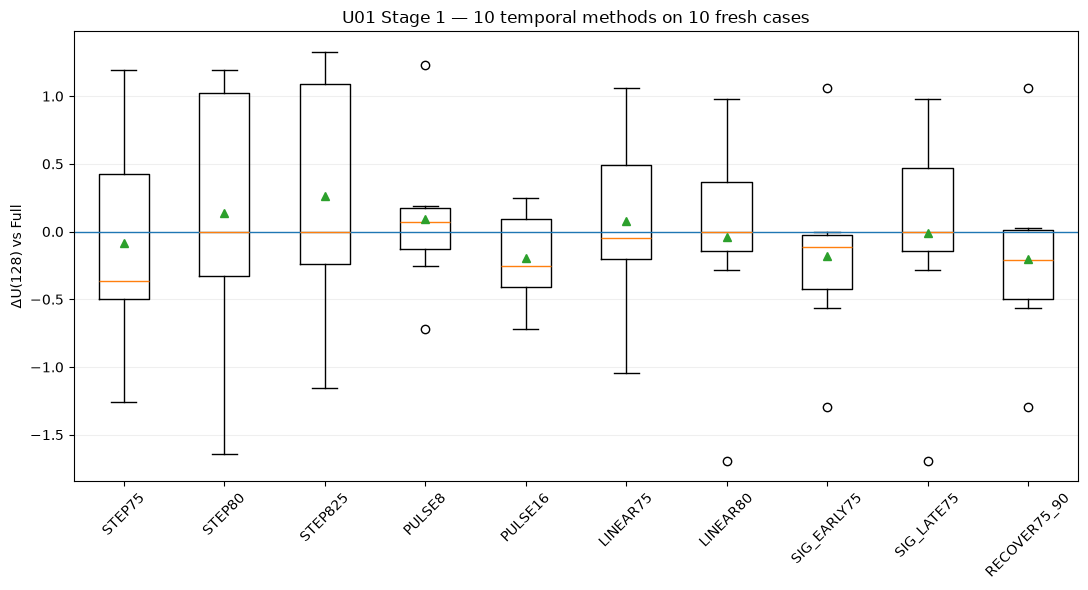

In [8]:
# Safe model swap: generator -> scorer.
if "gmodel" in globals():
    del gmodel

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if "stok" not in globals():
    stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)

smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,
    dtype=dtype,
    low_cpu_mem_usage=True
).to(device).eval()
if torch.cuda.is_available():torch.cuda.empty_cache()

stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

@torch.inference_mode()
def score_u128(text):
    ids=stok(str(text),add_special_tokens=False)["input_ids"]
    if len(ids)<256:return np.nan
    ids=ids[:256];pos=np.unique(np.linspace(128,255,8,dtype=int));loss={}
    for k in [8,32,128]:
        x=torch.tensor([ids[t-k:t] for t in pos],device=device)
        y=torch.tensor([ids[t] for t in pos],device=device)
        logits=smodel(input_ids=x,logits_to_keep=1).logits[:,-1,:].float()
        ll=F.log_softmax(logits,-1)[torch.arange(len(y),device=device),y]
        loss[k]=float((-ll).mean().cpu())
    return loss[8]-loss[128]

def add_u(df,path):
    if path.exists():return pd.read_parquet(path)
    z=df.copy()
    z["U128"]=[score_u128(x) for x in tqdm(z.generated_text,total=len(z),desc=path.stem)]
    z.to_parquet(path,index=False)
    return z

s1u=add_u(s1,OUT/"stage1_U128.parquet")
w=s1u.pivot(index="source_id",columns="method",values="U128")
d1=w.subtract(w["FULL"],axis=0).drop(columns="FULL")
d1.to_csv(OUT/"stage1_delta_U128.csv")

summary1=[]
for m in METHODS:
    x=d1[m].dropna()
    summary1.append({
        "method":m,"eligible_n":len(x),"mean_delta_U128":x.mean(),
        "median_delta_U128":x.median(),"negative_fraction":(x<0).mean() if len(x) else np.nan
    })
summary1=pd.DataFrame(summary1).merge(stage1_rank,on="method",how="left")
display(summary1.sort_values(["survives","mean_delta_U128"],ascending=[False,True]))
summary1.to_csv(OUT/"stage1_method_summary.csv",index=False)

data=[];tick_labels=[]
for m in METHODS:
    x=d1[m].dropna().to_numpy(float)
    if len(x):
        data.append(x)
        tick_labels.append(m)

fig,ax=plt.subplots(figsize=(11,6))
ax.boxplot(data,tick_labels=tick_labels,showmeans=True)
ax.axhline(0,linewidth=1)
ax.set(
    ylabel="ΔU(128) vs Full",
    title="U01 Stage 1 — 10 temporal methods on 10 fresh cases"
)
ax.tick_params(axis="x",rotation=45)
ax.grid(axis="y",alpha=.2)
fig.tight_layout()

for folder in [OUT,FIG]:
    fig.savefig(folder/"U01_stage1_delta_U128.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U01_stage1_delta_U128.pdf",bbox_inches="tight")

plt.show()

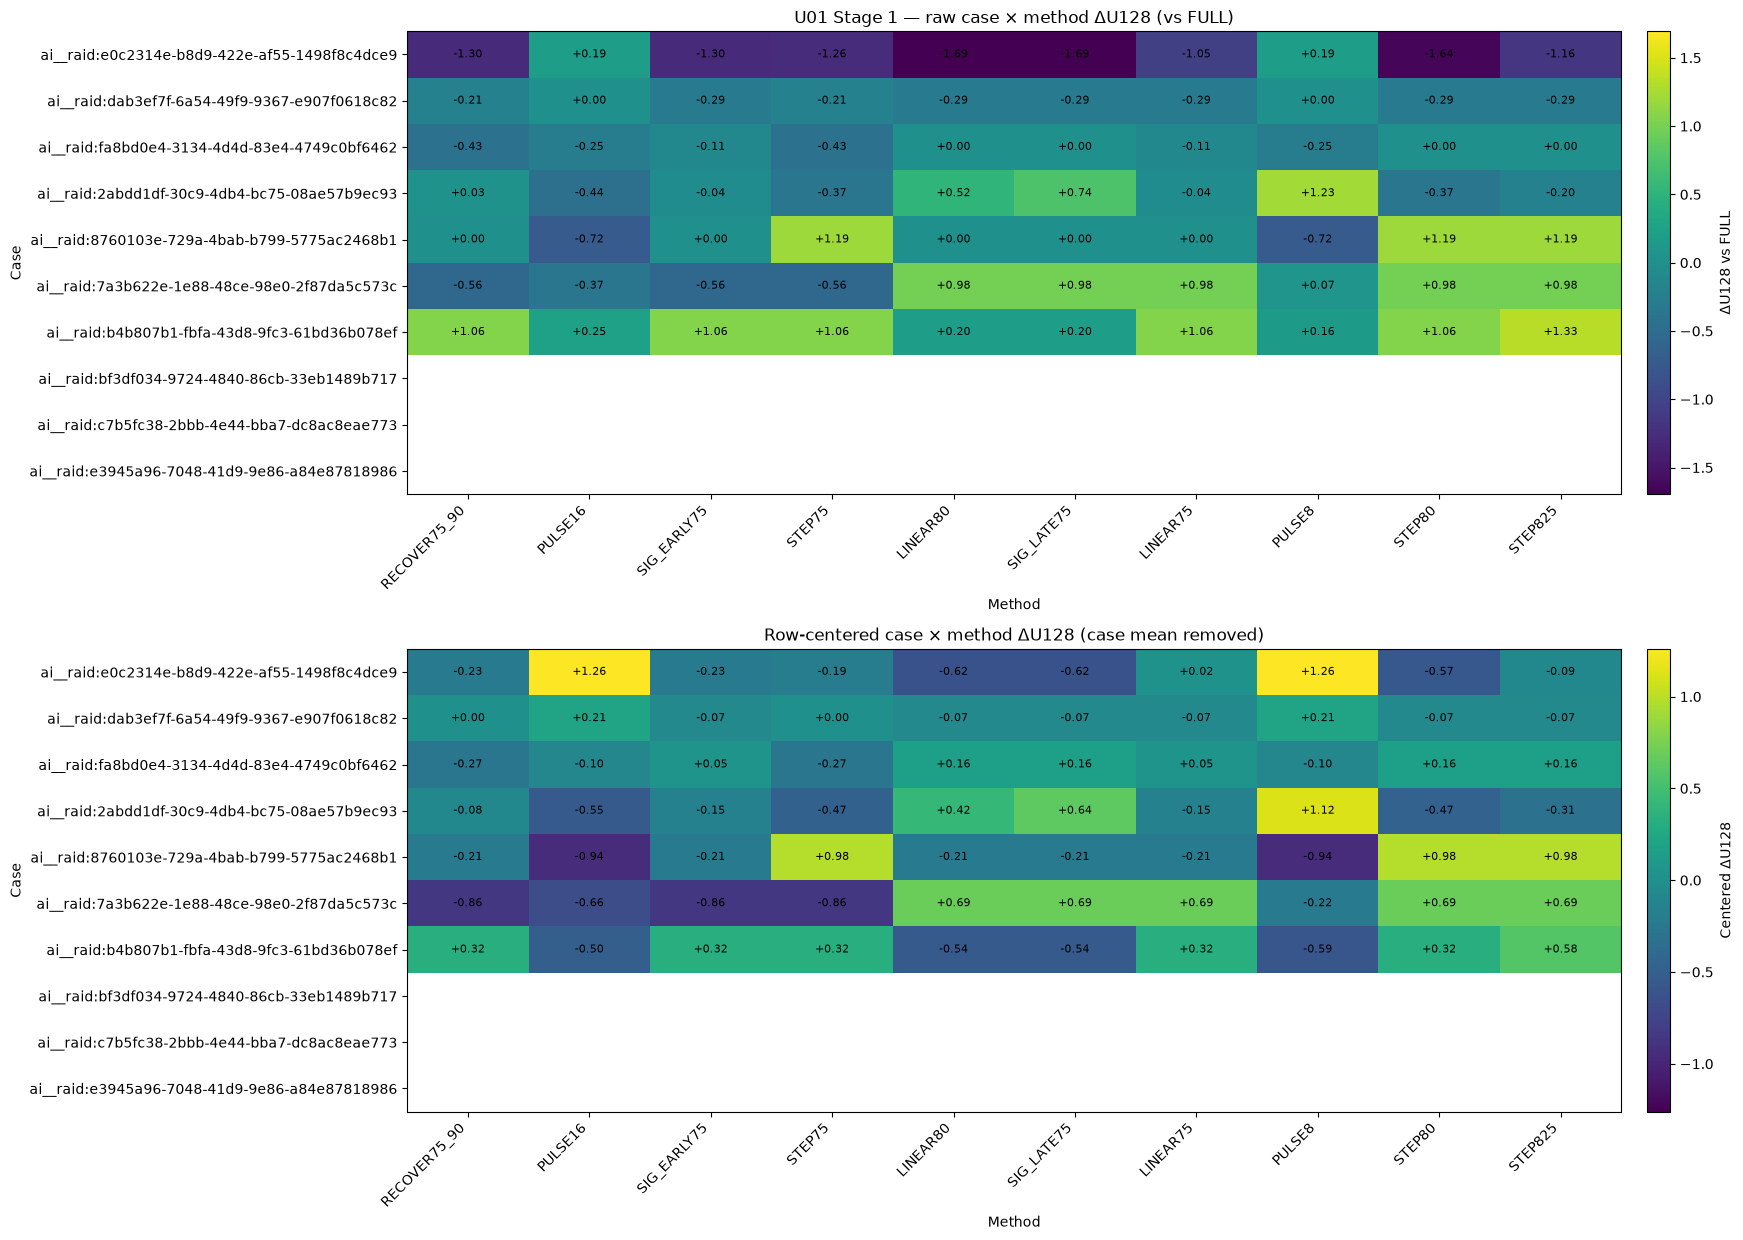

method,RECOVER75_90,PULSE16,SIG_EARLY75,STEP75,LINEAR80,SIG_LATE75,LINEAR75,PULSE8,STEP80,STEP825
source_id,,,,,,,,,,
ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,-1.295691,0.189783,-1.295691,-1.258098,-1.693823,-1.693823,-1.047546,0.189783,-1.640937,-1.157463
ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,-0.208875,0.000000,-0.286654,-0.208875,-0.286654,-0.286654,-0.286654,0.000000,-0.286654,-0.286654
ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,-0.426226,-0.254756,-0.113534,-0.426226,0.000000,0.000000,-0.113534,-0.254756,0.000000,0.000000
ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,0.026515,-0.442460,-0.043938,-0.367434,0.524204,0.741962,-0.043938,1.229234,-0.365238,-0.199264
ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,0.000000,-0.722875,0.000000,1.191737,0.000000,0.000000,0.000000,-0.722875,1.191737,1.191737
ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,-0.563646,-0.369478,-0.563646,-0.563646,0.982287,0.982287,0.982287,0.068764,0.982287,0.982287
ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,1.061325,0.248247,1.061325,1.061325,0.202067,0.202067,1.061325,0.156127,1.061325,1.327597
ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# Case × method view of Stage 1 ΔU128, to see whether structure is case-specific or just noise.
# Assumes:
#   - d1 has one row per eligible case and one column per method, containing ΔU128 vs FULL
#   - METHODS is the list of method names
#   - summary1 exists (used only for ordering methods)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Order methods from best to worst by mean effect (more negative = stronger U reduction).
method_order = (
    summary1.sort_values(["survives","mean_delta_U128"], ascending=[False, True])["method"]
    .tolist()
)
method_order = [m for m in method_order if m in d1.columns]

# Pull a clean matrix.
meta_cols = [c for c in ["case_id","domain","source_id"] if c in d1.columns]
plot_df = d1[meta_cols + method_order].copy()

# Nice row labels.
def make_row_label(r):
    parts = []
    if "case_id" in r.index: parts.append(str(r["case_id"]))
    if "domain" in r.index:  parts.append(str(r["domain"]))
    return " | ".join(parts) if parts else str(r.name)

row_labels = plot_df.apply(make_row_label, axis=1).tolist()

mat = plot_df[method_order].astype(float)
centered = mat.sub(mat.mean(axis=1), axis=0)   # removes per-case baseline to expose method pattern

# Sort cases by overall mean effect just for readability.
row_order = mat.mean(axis=1).sort_values().index
mat = mat.loc[row_order]
centered = centered.loc[row_order]
row_labels = [row_labels[list(plot_df.index).index(i)] for i in row_order]

# Shared color scale for raw heatmap.
finite_vals = mat.to_numpy().astype(float)
v = np.nanmax(np.abs(finite_vals)) if np.isfinite(finite_vals).any() else 1.0
v = max(v, 1e-6)

fig, axes = plt.subplots(2, 1, figsize=(1.35*len(method_order)+4, 0.65*len(mat)+6))

# ---------------- Raw ΔU128 ----------------
im0 = axes[0].imshow(mat.to_numpy(), aspect="auto", vmin=-v, vmax=v)
axes[0].set_title("U01 Stage 1 — raw case × method ΔU128 (vs FULL)")
axes[0].set_xticks(range(len(method_order)))
axes[0].set_xticklabels(method_order, rotation=45, ha="right")
axes[0].set_yticks(range(len(row_labels)))
axes[0].set_yticklabels(row_labels)
axes[0].set_xlabel("Method")
axes[0].set_ylabel("Case")

for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat.iat[i, j]
        txt = "" if pd.isna(val) else f"{val:+.2f}"
        axes[0].text(j, i, txt, ha="center", va="center", fontsize=8)

cbar0 = fig.colorbar(im0, ax=axes[0], fraction=0.03, pad=0.02)
cbar0.set_label("ΔU128 vs FULL")

# ---------------- Row-centered ΔU128 ----------------
vc = centered.to_numpy().astype(float)
vc_abs = np.nanmax(np.abs(vc)) if np.isfinite(vc).any() else 1.0
vc_abs = max(vc_abs, 1e-6)

im1 = axes[1].imshow(centered.to_numpy(), aspect="auto", vmin=-vc_abs, vmax=vc_abs)
axes[1].set_title("Row-centered case × method ΔU128 (case mean removed)")
axes[1].set_xticks(range(len(method_order)))
axes[1].set_xticklabels(method_order, rotation=45, ha="right")
axes[1].set_yticks(range(len(row_labels)))
axes[1].set_yticklabels(row_labels)
axes[1].set_xlabel("Method")
axes[1].set_ylabel("Case")

for i in range(centered.shape[0]):
    for j in range(centered.shape[1]):
        val = centered.iat[i, j]
        txt = "" if pd.isna(val) else f"{val:+.2f}"
        axes[1].text(j, i, txt, ha="center", va="center", fontsize=8)

cbar1 = fig.colorbar(im1, ax=axes[1], fraction=0.03, pad=0.02)
cbar1.set_label("Centered ΔU128")

fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(folder/"U01_case_method_heatmap.png", dpi=300, bbox_inches="tight")
    fig.savefig(folder/"U01_case_method_heatmap.pdf", bbox_inches="tight")

plt.show()

display(mat)

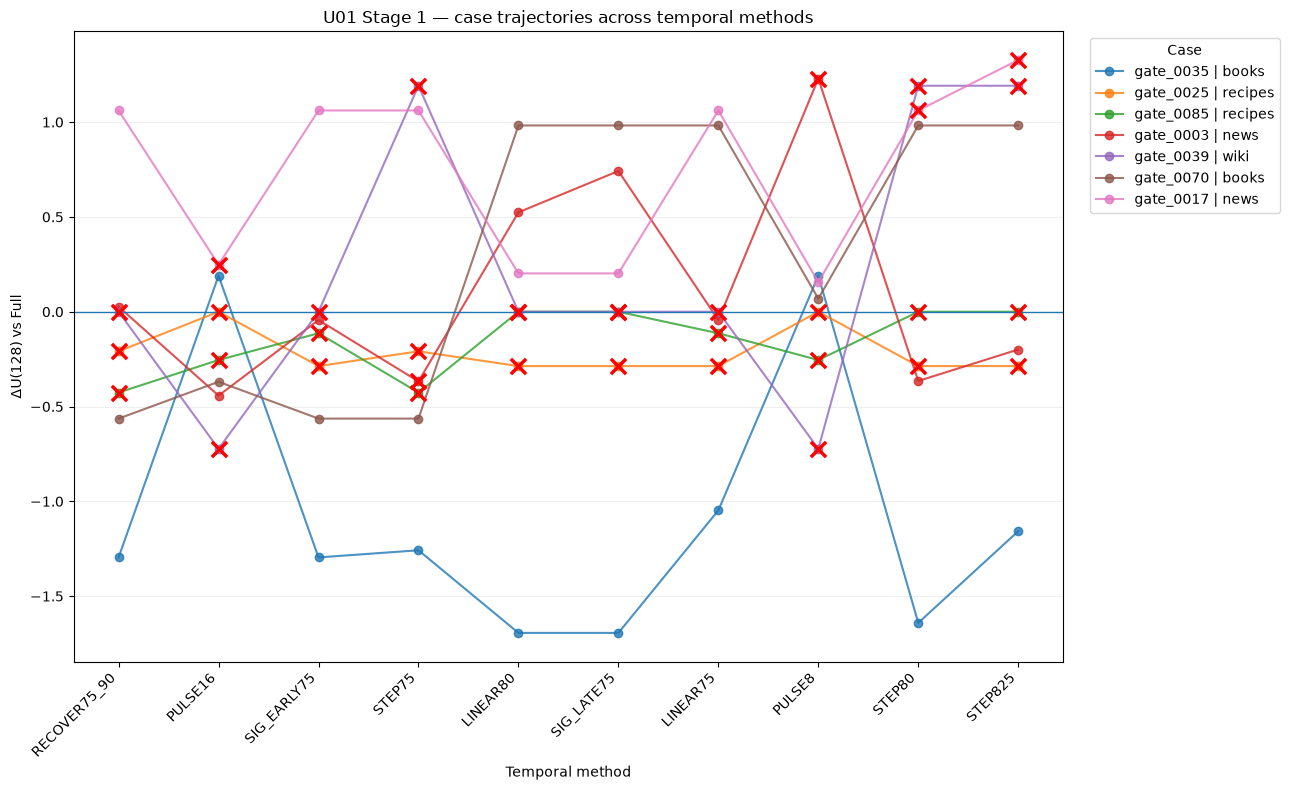

Red X = non-EOS / max-token result


,case_id,domain,method,delta_U128,stop_reason,generator_tokens
0,gate_0003,news,PULSE8,1.229234,max_tokens,480
1,gate_0003,news,STEP75,-0.367434,max_tokens,480
2,gate_0017,news,PULSE16,0.248247,max_tokens,480
3,gate_0017,news,STEP80,1.061325,max_tokens,480
4,gate_0017,news,STEP825,1.327597,max_tokens,480
5,gate_0025,recipes,LINEAR75,-0.286654,max_tokens,480
6,gate_0025,recipes,LINEAR80,-0.286654,max_tokens,480
7,gate_0025,recipes,PULSE16,0.000000,max_tokens,480
8,gate_0025,recipes,PULSE8,0.000000,max_tokens,480
9,gate_0025,recipes,RECOVER75_90,-0.208875,max_tokens,480


In [11]:
# Stage-1 spaghetti plot: one line per case, non-EOS observations marked red.
import numpy as np,pandas as pd,matplotlib.pyplot as plt

# d1: index=source_id, columns=methods, values=ΔU128 vs FULL
method_order=summary1.sort_values("mean_delta_U128").method.tolist()
method_order=[m for m in method_order if m in d1.columns]

# Convert ΔU matrix to long form.
long_df=(
    d1[method_order]
    .reset_index()
    .melt(id_vars="source_id",var_name="method",value_name="delta_U128")
)

# Attach case/domain metadata.
meta=(
    s1[["source_id","case_id","domain"]]
    .drop_duplicates("source_id")
)
long_df=long_df.merge(meta,on="source_id",how="left",validate="many_to_one")

# Attach generation termination status for each case × method.
gen_meta=(
    s1[s1.method.ne("FULL")]
    [["source_id","method","stop_reason","generator_tokens","first_override_step"]]
    .drop_duplicates(["source_id","method"])
)
long_df=long_df.merge(
    gen_meta,on=["source_id","method"],how="left",validate="one_to_one"
)

long_df=long_df[long_df.delta_U128.notna()].copy()
long_df["non_eos"]=long_df.stop_reason.ne("eos")

# Order cases by their average ΔU just to make crossings easier to inspect.
case_order=(
    long_df.groupby("source_id").delta_U128.mean()
    .sort_values().index.tolist()
)

x=np.arange(len(method_order))
fig,ax=plt.subplots(figsize=(13,8))

for sid in case_order:
    g=long_df[long_df.source_id.eq(sid)].set_index("method").reindex(method_order)
    y=g.delta_U128.to_numpy(float)

    case_id=g.case_id.dropna().iloc[0]
    domain=g.domain.dropna().iloc[0]
    ax.plot(
        x,y,marker="o",linewidth=1.5,alpha=.8,
        label=f"{case_id} | {domain}"
    )

    # Non-EOS results are potentially confounded: overlay a red X.
    bad=g.non_eos.fillna(False).to_numpy(bool)&np.isfinite(y)
    if bad.any():
        ax.scatter(
            x[bad],y[bad],
            marker="x",s=120,linewidths=2.5,
            color="red",zorder=10
        )

ax.axhline(0,linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(method_order,rotation=45,ha="right")
ax.set(
    xlabel="Temporal method",
    ylabel="ΔU(128) vs Full",
    title="U01 Stage 1 — case trajectories across temporal methods"
)
ax.grid(axis="y",alpha=.2)
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left",title="Case")
fig.tight_layout()

for folder in [OUT,FIG]:
    fig.savefig(folder/"U01_stage1_spaghetti_delta_U128.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U01_stage1_spaghetti_delta_U128.pdf",bbox_inches="tight")

plt.show()

print("Red X = non-EOS / max-token result")
display(
    long_df[long_df.non_eos][
        ["case_id","domain","method","delta_U128","stop_reason","generator_tokens"]
    ].sort_values(["case_id","method"]).reset_index(drop=True)
)

In [12]:
# Inspect all Stage-1 recipe failures before changing anything.
recipe_cases=s1[s1.domain.eq("recipes")].case_id.unique().tolist()
print("Recipe cases:",recipe_cases)

for case_id in recipe_cases:
    g=s1[s1.case_id.eq(case_id)].copy()
    prompt=stage1.loc[stage1.case_id.eq(case_id),"prompt"].iloc[0]

    print("\n"+"="*140)
    print(f"{case_id} | recipes")
    print("\nPROMPT:")
    print(prompt)

    full=g[g.method.eq("FULL")].iloc[0]
    print("\n"+"-"*140)
    print(f"FULL | stop={full.stop_reason} | tokens={full.generator_tokens}")
    print(full.generated_text)

    failed=g[(g.method.ne("FULL"))&(g.stop_reason.ne("eos"))].copy()
    print(f"\nFAILED TEMPORAL METHODS: {len(failed)}")

    for r in failed.sort_values("method").itertuples(index=False):
        du=np.nan
        if case_id in set(meta.case_id) if "meta" in globals() else False:
            pass

        # Get ΔU from d1 by source_id if available.
        try:
            du=float(d1.loc[r.source_id,r.method])
        except Exception:
            du=np.nan

        print("\n"+"-"*140)
        print(
            f"{r.method} | stop={r.stop_reason} | tokens={r.generator_tokens} | "
            f"first_override={r.first_override_step} | overrides={r.override_count} | "
            f"ΔU128={du:+.3f}" if np.isfinite(du)
            else
            f"{r.method} | stop={r.stop_reason} | tokens={r.generator_tokens} | "
            f"first_override={r.first_override_step} | overrides={r.override_count}"
        )
        print(r.generated_text)

Recipe cases: ['gate_0085', 'gate_0025']

gate_0085 | recipes

PROMPT:
Write a recipe for "Broccoli And Garlic-Ricotta Toasts With Hot Honey ".

--------------------------------------------------------------------------------------------------------------------------------------------
FULL | stop=max_tokens | tokens=480
Broccoli And Garlic-Ricotta Toasts With Hot Honey Recipe

Ingredients:
- 4 slices of whole-grain bread
- 1 cup of ricotta cheese
- 1/2 cup of grated Parmesan cheese
- 1/4 cup of chopped fresh parsley
- 1/4 cup of chopped fresh basil
- 1/4 cup of chopped fresh dill
- 1/4 cup of chopped fresh mint
- 1/4 cup of chopped fresh chives
- 1/4 cup of chopped fresh cilantro
- 1/4 cup of chopped fresh thyme
- 1/4 cup of chopped fresh rosemary
- 1/4 cup of chopped fresh sage
- 1/4 cup of chopped fresh oregano
- 1/4 cup of chopped fresh basil
- 1/4 cup of chopped fresh parsley
- 1/4 cup of chopped fresh dill
- 1/4 cup of chopped fresh mint
- 1/4 cup of chopped fresh chives
- 1/4 cup

# STOP RIGHT HERE

## Stage 2 — survivors × 10 additional fresh cases

In [ ]:
del smodel;gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()
gmodel=AutoModelForCausalLM.from_pretrained(
    GENERATOR,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

S2_PATH=OUT/"stage2_generations.parquet"
s2=pd.read_parquet(S2_PATH) if S2_PATH.exists() else pd.DataFrame()
done=set(zip(s2.source_id.astype(str),s2.method.astype(str))) if len(s2) else set()
rows=s2.to_dict("records") if len(s2) else []
required2=["FULL"]+survivors
pbar=tqdm(total=len(stage2)*len(required2),initial=len(done),desc="U01 stage2")

for src in stage2.itertuples(index=False):
    for method in required2:
        key=(str(src.source_id),method)
        if key in done:continue
        if method=="FULL":
            ids,stop=generate_full(src.prompt);first=np.nan;active=0;over=0;mean_lam=1.
        else:
            ids,stop,first,active,over,mean_lam=generate_method(src.prompt,method)
        text=gtok.decode(ids,skip_special_tokens=True)
        rows.append({
            "stage":2,"case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "method":method,"generated_text":text,"generator_tokens":len(ids),
            "stop_reason":stop,"first_override_step":first,"active_steps":active,
            "override_count":over,"mean_lambda_full":mean_lam,
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })
        s2=pd.DataFrame(rows);s2.to_parquet(S2_PATH,index=False);pbar.update(1)

pbar.close()
assert len(s2)==len(stage2)*len(required2)

display(
    s2[s2.method.ne("FULL")].groupby("method")
    .agg(non_eos=("stop_reason",lambda x:(x!="eos").sum()),
         eos_rate=("stop_reason",lambda x:(x=="eos").mean()),
         mean_tokens=("generator_tokens","mean"))
    .reindex(survivors)
)


## Combined 20-case \(\Delta U(128)\) graph for surviving methods

In [ ]:
del gmodel;gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

s2u=add_u(s2,OUT/"stage2_U128.parquet")
all_u=pd.concat([s1u[s1u.method.isin(["FULL"]+survivors)],s2u],ignore_index=True)
w=all_u.pivot(index="source_id",columns="method",values="U128")
delta=w.subtract(w["FULL"],axis=0).drop(columns="FULL")
delta.to_csv(OUT/"combined20_delta_U128.csv")

gen_all=pd.concat([s1[s1.method.isin(survivors)],s2[s2.method.isin(survivors)]],ignore_index=True)
rank20=(
    gen_all.groupby("method")
    .agg(cases=("source_id","size"),
         non_eos=("stop_reason",lambda x:(x!="eos").sum()),
         eos_rate=("stop_reason",lambda x:(x=="eos").mean()),
         mean_tokens=("generator_tokens","mean"))
    .reset_index()
)

rows=[]
for m in survivors:
    x=delta[m].dropna()
    rows.append({
        "method":m,"eligible_U_n":len(x),
        "mean_delta_U128":x.mean(),"median_delta_U128":x.median(),
        "negative_n":int((x<0).sum()),"negative_fraction":(x<0).mean() if len(x) else np.nan
    })
final_summary=pd.DataFrame(rows).merge(rank20,on="method",how="left")
final_summary=final_summary.sort_values(["non_eos","mean_delta_U128"])
final_summary.to_csv(OUT/"combined20_method_summary.csv",index=False)
display(final_summary)

data=[];labels=[]
for m in survivors:
    x=delta[m].dropna().to_numpy(float)
    if len(x):data.append(x);labels.append(m)

fig,ax=plt.subplots(figsize=(11,6))
ax.boxplot(data,labels=labels,showmeans=True)
ax.axhline(0,linewidth=1)
ax.set(ylabel="ΔU(128) vs Full",title="U01 — surviving temporal methods across 20 fresh cases")
ax.tick_params(axis="x",rotation=45);ax.grid(axis="y",alpha=.2);fig.tight_layout()
for folder in [OUT,FIG]:
    fig.savefig(folder/"U01_combined20_delta_U128.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U01_combined20_delta_U128.pdf",bbox_inches="tight")
plt.show()


## Manual lobotomization review

Set `REVIEW_METHOD` to any surviving method. This renders Full vs candidate side-by-side for every U01 case.


In [ ]:
REVIEW_METHOD=survivors[0]  # change manually
review_gen=pd.concat([s1,s2],ignore_index=True)
assert REVIEW_METHOD in review_gen.method.unique()

for case_id,g in review_gen[review_gen.method.isin(["FULL",REVIEW_METHOD])].groupby("case_id",sort=True):
    if set(g.method)!={"FULL",REVIEW_METHOD}:continue
    full=g[g.method.eq("FULL")].iloc[0]
    cand=g[g.method.eq(REVIEW_METHOD)].iloc[0]
    prompt=cohort20.loc[cohort20.case_id.eq(case_id),"prompt"].iloc[0]
    block=f"""
    <div style="border:1px solid #aaa;border-radius:8px;padding:12px;margin:16px 0;">
      <h3>{html.escape(str(case_id))} — {html.escape(str(full.domain))} — {html.escape(REVIEW_METHOD)}</h3>
      <div style="background:#f4f4f4;padding:8px;white-space:pre-wrap;"><b>PROMPT</b><br>{html.escape(str(prompt))}</div>
      <div style="display:grid;grid-template-columns:1fr 1fr;gap:12px;margin-top:10px;">
        <div style="border:1px solid #ccc;padding:10px;white-space:pre-wrap;"><b>FULL</b><br><br>{html.escape(str(full.generated_text))}</div>
        <div style="border:1px solid #ccc;padding:10px;white-space:pre-wrap;"><b>{html.escape(REVIEW_METHOD)}</b><br>
        stop={html.escape(str(cand.stop_reason))}, tokens={cand.generator_tokens}<br><br>{html.escape(str(cand.generated_text))}</div>
      </div>
    </div>
    """
    display(HTML(block))
